# 03: Modeling Graduation Risk

**Question:** Using only information available at the end of a student's first 9th-grade year, how well can we identify students who will finish high school with fewer than 24 credits?

**Approach:** Audit the data, split by cohort, handle missing values inside a pipeline, then climb a ladder of models: a majority-class baseline, a rule a counselor could apply by hand, logistic regression, Random Forest, and XGBoost. Each model has to beat the one below it to justify its added complexity. Results are checked against the synthetic answer key only at the end, after every model is fit.

## 0. Setup

Loads the cleaned one-row-per-student file from notebook 02. `DATA_SOURCE` matches the switch in notebook 02: the public repo runs on synthetic data, and real district runs read from the gitignored `data/` folder. All features describe a student as of the end of their first 9th-grade year.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

DATA_SOURCE = "synthetic"   # "synthetic" for the public repo, "real" for local district runs
RANDOM_STATE = 42

# Notebooks live in notebooks/, so data folders are one level up
data_dir = "../synthetic_data" if DATA_SOURCE == "synthetic" else "../data"
students = pd.read_csv(f"{data_dir}/students.csv", index_col="Student ID")

FEATURES = ["gpa_9", "pass_rate_9", "credits_9", "absence_rate_9", "met_ela_8", "met_math_8"]
TARGET = "earned_24"

print(students.shape)
students.head()

(450, 9)


,cohort,hs_credits,earned_24,gpa_9,pass_rate_9,credits_9,absence_rate_9,met_ela_8,met_math_8
Student ID,,,,,,,,,
1001754,2024,24.25,1,2.928571,0.928571,6.5,0.022857,1.0,1.0
1002162,2020,23.25,0,2.538462,0.800000,5.5,0.058480,1.0,1.0
1002616,2024,21.00,0,1.642857,0.857143,6.0,0.017647,NaN,0.0
1004242,2023,16.00,0,1.461538,0.928571,6.5,0.183432,0.0,0.0
1005060,2017,25.00,1,1.500000,0.866667,6.0,0.132948,1.0,1.0


## 1. Audit before modeling

Nothing is fit in this section. The goal is to learn what the data allows before making decisions.

### 1a. Students and target rate per cohort

In [2]:
cohort_summary = students.groupby("cohort").agg(
    n_students=("earned_24", "count"),
    pct_earned_24=("earned_24", "mean"),
)
cohort_summary

,n_students,pct_earned_24
cohort,,
2013,44,0.340909
2014,35,0.314286
2015,43,0.418605
2016,32,0.562500
2017,31,0.483871
2018,42,0.404762
2019,30,0.500000
2020,36,0.416667
2021,36,0.416667


**Findings.** The data covers 12 senior-year cohorts (2013 to 2024) of 30 to 47 students each. The share earning 24+ credits ranges from 31% to 56% by cohort. With about 35 students per cohort, a swing of this size is consistent with chance, and in the synthetic data it is chance: notebook 01 assigns each student a cohort at random, with no trend across years.

Every cohort is complete. Notebook 01 simulates each student's full path through their final senior year, so no credit total is still in progress. In real district data this must be checked against the export date, since a cohort still in its senior year would show students as falling short who simply have not finished.

**Implication for the split.** Holding out a single cohort would leave a test set of fewer than 50 students, too small for stable precision and recall. The test set will be the three most recent cohorts.

### 1b. Missingness by feature and cohort

In [3]:
# Missing values per feature, all students
students[FEATURES].isna().sum()

gpa_9              6
pass_rate_9        6
credits_9          6
absence_rate_9    19
met_ela_8         72
met_math_8        86
dtype: int64

In [4]:
# Missing values per feature, by cohort
students[FEATURES].isna().groupby(students["cohort"]).sum()

,gpa_9,pass_rate_9,credits_9,absence_rate_9,met_ela_8,met_math_8
cohort,,,,,,
2013,2,2,2,4,8,9
2014,1,1,1,3,6,4
2015,0,0,0,0,4,8
2016,0,0,0,0,5,7
2017,0,0,0,3,6,7
2018,0,0,0,1,7,4
2019,0,0,0,3,7,5
2020,1,1,1,1,7,11
2021,0,0,0,0,7,12


In [5]:
# Are the students missing 9th-grade course data the same ones missing attendance?
no_course = students["gpa_9"].isna()
no_absence = students["absence_rate_9"].isna()
(no_course & no_absence).sum()

np.int64(6)

**Findings.** Six students have no 9th-grade course records, and all six also lack 9th-grade attendance, which suggests they were not enrolled in the district that year. Another 13 students are missing attendance but have course records. Missing 8th-grade state test results are the largest gap (72 ELA and 86 math, out of 450), most likely students who arrived in the district after 8th grade.

Missingness is spread across all 12 cohorts rather than concentrated in a few, so a split by cohort will not push missing values onto one side.

**Scope decision.** The six students without 9th-grade course data are excluded. This model is meant to score students at the end of 9th grade, and a student with no 9th-grade record in the district could not be scored at that point in practice.

### 1c. Is missingness itself a signal?

In [6]:
# Share earning 24+ credits, split by whether the 8th-grade ELA result is missing
students.groupby(students["met_ela_8"].isna())["earned_24"].mean()

met_ela_8
False    0.436508
True     0.416667
Name: earned_24, dtype: float64

In [7]:
# Same for 8th-grade math
students.groupby(students["met_math_8"].isna())["earned_24"].mean()

met_math_8
False    0.447802
True     0.372093
Name: earned_24, dtype: float64

**Findings.** Students missing 8th-grade ELA results earned 24+ credits at nearly the same rate as students with results (42% vs 44%). For math the gap is larger (37% vs 45%), but with 86 missing students it is within what chance could produce.

**Decision.** Missing values will be filled with the training-set median, and a missing-indicator column will be added for each feature with gaps. The evidence that missingness predicts the outcome is weak here, but indicators are cheap and let the model use the signal if it exists. In real district data, a missing 8th-grade score often means a student transferred in, which may carry more information than it does in this synthetic data. Because the 8th-grade features are 0/1, the median fill is always 0 or 1, never a fractional value. Imputation happens inside a pipeline fit on training data only, so test-set values never inform the fill values.

## 2. Train/test split by cohort

The split happens before any imputation or scaling, so nothing learned from the test set can leak into training. Training uses the older cohorts and testing uses the most recent ones, which mirrors how a district would use the model: fit on past classes, then score an incoming one.

In [8]:
# Scope decision from 1b: drop students with no 9th-grade course data
model_df = students[students["gpa_9"].notna()]
print(len(model_df))  # expect 444

# Hold out the three most recent cohorts as the test set
test_cohorts = [2022, 2023, 2024]
is_test = model_df["cohort"].isin(test_cohorts)

# Features and target for each side of the split (~ means "not")
X_train = model_df.loc[~is_test, FEATURES]
X_test  = model_df.loc[is_test, FEATURES]
y_train = model_df.loc[~is_test, TARGET]
y_test  = model_df.loc[is_test, TARGET]

# Size and share earning 24+ credits on each side
print(len(X_train), len(X_test), y_train.mean(), y_test.mean())

444
325 119 0.4276923076923077 0.47058823529411764


**Split.** After dropping the six students with no 9th-grade course data, 444 students remain. Training uses the 2013 to 2021 cohorts (325 students, 42.8% earning 24+ credits) and testing uses 2022 to 2024 (119 students, 47.1%). The four-point gap in success rates is within what chance produces at these sizes.

**Weakness.** The test set holds 63 at-risk students, so each one moves at-risk recall by about 1.6 percentage points. Small differences between models on the test set should not be over-read.

## 3. How we will score models

**Positive class.** The target is coded with success (24+ credits) as 1, but the purpose of an early-warning list is to find students who are at risk. For scoring, the label is flipped so that 1 means *did not* earn 24 credits. Precision and recall below always refer to the at-risk group.

In [9]:
# At-risk label: 1 = did NOT earn 24 credits, 0 = did
y_train_risk = 1 - y_train
y_test_risk = 1 - y_test

**Which metric gets priority.** Missing a student who ends up short is the more costly error: that student gets no extra support until it may be too late to recover credits. Flagging a student who would have been fine costs a counselor check-in. So **recall on the at-risk group** is the priority metric, with precision as a guardrail, since a list that flags nearly everyone is not useful to a counselor with a full caseload. ROC AUC is also reported, because it measures how well a model ranks students regardless of where the flagging cutoff is set.

In [10]:
# Shared scoring function: every model is evaluated the same way
# y_score: a probability or score where higher = more at risk (None if the model has none)
def evaluate(name, y_true, y_pred, y_score=None):
    row = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }
    if y_score is not None:
        row["roc_auc"] = roc_auc_score(y_true, y_score)
    return row

# Every model below appends its evaluate(...) result here
results = []

## 4. Model ladder

### Rung 1: Majority-class baseline

The simplest possible "model": predict the most common outcome for every student. Any real model has to beat this.

In [11]:
# Predict the most common training outcome for every student, then score it
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train_risk)

dummy_pred = dummy.predict(X_test)
dummy_score = dummy.predict_proba(X_test)[:, 1]

results.append(evaluate("Majority class", y_test_risk, dummy_pred, dummy_score))
results[-1]

{'model': 'Majority class',
 'accuracy': 0.5294117647058824,
 'precision': 0.5294117647058824,
 'recall': 1.0,
 'f1': 0.6923076923076923,
 'roc_auc': np.float64(0.5)}

**Findings.** Because 57% of training students are at risk, the majority-class baseline flags every test student. That gives it perfect recall (1.0) but precision of only 0.53, the at-risk share of the test set, and an AUC of 0.5, since it gives every student the same score and cannot rank anyone. This shows why recall alone cannot judge a model here: flagging everyone maximizes it while giving a counselor no useful information. Its F1 (0.69) is also nearly identical to the credits rule's below, so F1 does not separate a useless model from a useful one in this setting. The comparisons that follow rely on recall, precision, and AUC together.

### Rung 2: A rule a counselor could apply by hand

Many real on-track indicators are a single cutoff, such as "fewer than N credits at the end of 9th grade." If a model cannot beat a rule like this, its added complexity is not justified.

In [12]:
# Flag students below 6 credits after 9th grade: 24 credits over 4 years = 6 per year
CUTOFF = 6

# Check the rule on training data first
train_flag = (X_train["credits_9"] < CUTOFF).astype(int)
print("train recall:", recall_score(y_train_risk, train_flag))
print("train precision:", precision_score(y_train_risk, train_flag))

# Apply the same rule, unchanged, to the test set
rule_pred = (X_test["credits_9"] < CUTOFF).astype(int)

# Score for AUC: higher must mean more at risk, and fewer credits = more risk, so negate
rule_score = -X_test["credits_9"]

results.append(evaluate("Credits rule (< 6)", y_test_risk, rule_pred, rule_score))
results[-1]

train recall: 0.6827956989247311
train precision: 0.8466666666666667


{'model': 'Credits rule (< 6)',
 'accuracy': 0.7058823529411765,
 'precision': 0.7692307692307693,
 'recall': 0.6349206349206349,
 'f1': 0.6956521739130435,
 'roc_auc': np.float64(0.8238378684807256)}

**Findings.** The rule flags any student with fewer than 6 credits after 9th grade, the pace needed to reach 24 credits in four years. The cutoff comes from the graduation requirement, not from the data, so no test-set information was used to choose it. On training data the rule caught 68% of at-risk students with 85% precision.

On the test set it flagged 52 students, 40 of whom were at risk: recall of 0.63 (40 of 63 at-risk students) and precision of 0.77. Its AUC of 0.82 means that, given one at-risk and one on-track student, the rule ranks the at-risk student higher 82% of the time. The drop from training to test is about three students, within the noise of a 119-student test set.

**This is the bar for every model that follows.** A model has to beat 0.82 AUC, or catch more at-risk students at similar precision, to justify being harder to explain than "fewer than 6 credits."

### Rung 3: Logistic regression

Imputation, missing indicators, and scaling all go inside a `Pipeline`, so they are fit on training data only and applied unchanged to the test set.

**Why scale.** scikit-learn's logistic regression applies a penalty that shrinks coefficients toward zero. That penalty is affected by each feature's units, so a feature measured on a large scale would be treated differently from one on a small scale. Standardizing puts every feature on the same footing. Tree-based models (Rungs 4 and 5) split on thresholds within one feature at a time, so rescaling a feature does not change them.

In [13]:
# Pipeline: median imputation with missing indicators -> standardize -> logistic regression
lr_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])

# Fit on training data, then predict a class and an at-risk probability for each test student
lr_pipe.fit(X_train, y_train_risk)
lr_pred = lr_pipe.predict(X_test)
lr_score = lr_pipe.predict_proba(X_test)[:, 1]

results.append(evaluate("Logistic regression", y_test_risk, lr_pred, lr_score))
results[-1]

{'model': 'Logistic regression',
 'accuracy': 0.7394957983193278,
 'precision': 0.7352941176470589,
 'recall': 0.7936507936507936,
 'f1': 0.7633587786259542,
 'roc_auc': np.float64(0.8112244897959183)}

**Results.** Logistic regression flagged 68 test students and caught 50 of the 63 at risk (recall 0.79, precision 0.74). That is 10 more at-risk students than the credits rule, but it also flags 16 more students overall, because the two approaches draw the "at risk" line in different places. AUC compares them regardless of where the line is drawn, and there the two are essentially tied (0.81 vs 0.82, a gap well within the noise of a 119-student test set). Using six features does not rank students better than one number a counselor could look up.

In [14]:
# Coefficients next to feature names, including the missing-indicator columns
# lr_pipe[:-1] is every step except the model, which is where the column names come from
feature_names = lr_pipe[:-1].get_feature_names_out()
coefs = lr_pipe.named_steps["model"].coef_[0]

pd.Series(coefs, index=feature_names).sort_values()

pass_rate_9                       -0.806677
gpa_9                             -0.670458
met_math_8                        -0.340366
credits_9                         -0.263655
met_ela_8                         -0.225855
absence_rate_9                    -0.050108
missingindicator_absence_rate_9   -0.045741
missingindicator_met_ela_8        -0.007583
missingindicator_met_math_8        0.147984
dtype: float64

**Coefficients.** Labels are coded so that positive means more risk. Pass rate, GPA, credits, and both 8th-grade tests are all protective, as expected. Two results stand out.

First, 9th-grade credits carries a small weight even though it powers the credits rule. Credits, pass rate, and GPA all measure whether a student passed their 9th-grade courses, so the model spreads their shared information across all three, and individual coefficients among overlapping features are not reliable on their own.

Second, absence rate is close to zero. Once course performance is known, attendance adds little, since students who miss school tend to show it in their grades. A missing 8th-grade math score leans slightly toward risk, consistent with the gap found in 1c.

### Rung 4: Random Forest

Same imputation step as logistic regression, with no scaler (see Rung 3).

In [15]:
# Pipeline: median imputation with missing indicators -> Random Forest (no scaler needed for trees)
rf_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("model", RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE)),
])

# Fit, predict, score, and append to results
rf_pipe.fit(X_train, y_train_risk)
rf_pred = rf_pipe.predict(X_test)
rf_score = rf_pipe.predict_proba(X_test)[:, 1]

results.append(evaluate("Random Forest", y_test_risk, rf_pred, rf_score))
results[-1]

{'model': 'Random Forest',
 'accuracy': 0.7058823529411765,
 'precision': 0.6944444444444444,
 'recall': 0.7936507936507936,
 'f1': 0.7407407407407407,
 'roc_auc': np.float64(0.7511337868480725)}

In [16]:
# Feature importances next to feature names
rf_names = rf_pipe[:-1].get_feature_names_out()
rf_importances = rf_pipe.named_steps["model"].feature_importances_

pd.Series(rf_importances, index=rf_names).sort_values(ascending=False)

gpa_9                              0.283911
absence_rate_9                     0.228024
pass_rate_9                        0.220379
credits_9                          0.137986
met_math_8                         0.044657
met_ela_8                          0.036829
missingindicator_met_math_8        0.022910
missingindicator_met_ela_8         0.018010
missingindicator_absence_rate_9    0.007293
dtype: float64

**Findings.** Random Forest underperformed both simpler models. It flagged 72 test students and caught 50 of the 63 at risk (recall 0.79, precision 0.69). That matches logistic regression's recall, but only by flagging four more students, and its AUC of 0.75 is below logistic regression (0.81) and the credits rule (0.82). The cause is overfitting (confirmed by the check in Rung 5): by default each tree splits until it nearly memorizes its training students, and with 325 students much of what it learns is noise that does not carry over to new cohorts. Limiting tree depth or leaf size might help, but choosing those settings by checking test-set scores would leak test information into the model. Tuning belongs in cross-validation on the training cohorts (see Section 7).

**Feature importances.** GPA, pass rate, and absence rate rank highest. The absence result conflicts with logistic regression, where absence carried almost no weight. Random Forest's built-in importance tends to favor features with many distinct values: absence rate is continuous, while credits come in half-credit steps and the 8th-grade results are 0/1. These importances also show no direction and split credit among overlapping features, so they are not read here as evidence that absence matters more than course performance.

### Rung 5: XGBoost

XGBoost can handle missing values on its own, but here it uses the same imputation step as the other models, so any difference in results reflects the model rather than a different missing-data approach.

In [17]:
# Pipeline: median imputation with missing indicators -> XGBoost
# Settings are conservative and fixed in advance (not tuned on the test set):
# shallow trees, small learning rate, moderate number of trees
xgb_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        random_state=RANDOM_STATE,
    )),
])

# Fit, predict, score, and append to results
xgb_pipe.fit(X_train, y_train_risk)
xgb_pred = xgb_pipe.predict(X_test)
xgb_score = xgb_pipe.predict_proba(X_test)[:, 1]

results.append(evaluate("XGBoost", y_test_risk, xgb_pred, xgb_score))
results[-1]

{'model': 'XGBoost',
 'accuracy': 0.680672268907563,
 'precision': 0.6712328767123288,
 'recall': 0.7777777777777778,
 'f1': 0.7205882352941176,
 'roc_auc': np.float64(0.7647392290249433)}

In [18]:
# Overfitting check: AUC on training students vs test students
for name, pipe in [("Logistic regression", lr_pipe), ("Random Forest", rf_pipe), ("XGBoost", xgb_pipe)]:
    train_auc = roc_auc_score(y_train_risk, pipe.predict_proba(X_train)[:, 1])
    test_auc = roc_auc_score(y_test_risk, pipe.predict_proba(X_test)[:, 1])
    print(f"{name}: train {train_auc:.3f}, test {test_auc:.3f}")

Logistic regression: train 0.850, test 0.811
Random Forest: train 1.000, test 0.751
XGBoost: train 0.971, test 0.765


**Findings.** XGBoost flagged 73 test students and caught 49 of the 63 at risk (recall 0.78, precision 0.67). Its AUC of 0.76 is slightly above Random Forest but below logistic regression (0.81) and the credits rule (0.82). Its settings were chosen in advance to limit overfitting (shallow trees, a small learning rate) and were not adjusted after seeing results.

**Overfitting check.** Comparing each model's AUC on training students with its AUC on test students shows why the tree models fall behind. Logistic regression scores 0.85 on training and 0.81 on test, a small drop. Random Forest scores a perfect 1.00 on training and 0.75 on test, and XGBoost scores 0.97 and 0.76. Both tree models largely memorized their 325 training students, and what they memorized did not carry over to new cohorts. With this little data, the flexibility that makes these models powerful works against them.

## 5. Comparing models

All models side by side on the same test set, sorted by AUC. AUC is the headline comparison because it does not depend on where each model draws its flagging line; recall alone would rank the majority-class baseline first, since it flags everyone.

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Credits rule (< 6),0.706,0.769,0.635,0.696,0.824
Logistic regression,0.739,0.735,0.794,0.763,0.811
XGBoost,0.681,0.671,0.778,0.721,0.765
Random Forest,0.706,0.694,0.794,0.741,0.751
Majority class,0.529,0.529,1.000,0.692,0.500


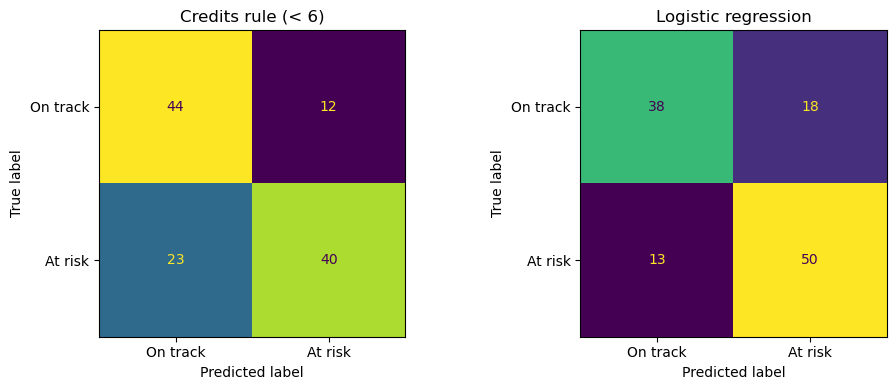

In [19]:
# One row per model, sorted by AUC
results_df = pd.DataFrame(results).set_index("model").sort_values("roc_auc", ascending=False).round(3)
display(results_df)

# Confusion matrices: the two top models side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [("Credits rule (< 6)", rule_pred), ("Logistic regression", lr_pred)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test_risk, pred, display_labels=["On track", "At risk"], ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Results.** The credits rule and logistic regression lead on AUC (0.82 and 0.81) and are effectively tied. Both tree models trail (0.76 and 0.75) because they overfit, and the majority-class baseline sits at 0.50.

**Recommendation.** For a district, the credits rule is the better first tool. It ranks students as well as any model here, a counselor can apply it from a transcript, and anyone can see why a student was flagged. Logistic regression is worth adding only where a ranked list is useful, for example to decide which of the flagged students to reach first.

**Choosing how many to flag.** At their default settings the two leaders flag different numbers of students: the rule flags 52 and catches 40 of the 63 at-risk students, while logistic regression flags 68 and catches 50. Neither cutoff is "correct." Lowering a model's cutoff flags more students, which raises recall and lowers precision; raising it does the reverse. In practice the cutoff should match how many students counselors can actually support.

## 6. Checking against the answer key

The answer key from notebook 01 is loaded only now, after every model is fit, and is used for evaluation only, never as features. It exists only for synthetic data.

The answer key records each student's true engagement at the end of 9th grade (the hidden driver behind every feature), their true credit total, and their true outcome. The true outcome can differ from the observed one, because notebook 01 drops some transferred-in credits from the records, the way real transcripts sometimes do.

In [20]:
# Answer key and generating parameters (synthetic data only)
if DATA_SOURCE == "synthetic":
    truth = pd.read_csv(f"{data_dir}/_truth_students.csv", index_col="student_id")
    with open(f"{data_dir}/generating_parameters.json") as f:
        params = json.load(f)
    print(truth.columns.tolist())

['cohort', 'entry_grade', 'origin', 'alt_entry_grade', 'retained_9', 'fifth_year', 'engagement_end_of_9th', 'transfer_credits_missing', 'hs_credits_true', 'earned_24_true']


In [21]:
if DATA_SOURCE == "synthetic":
    test_truth = truth.loc[X_test.index]

    # 1. Direction check: how strongly engagement drives each observed measure in notebook 01
    print({k: params[k] for k in ["pass_engagement", "absence_engagement", "test_engagement_weight"]})

    # 2. Reference point: rank test students by true end-of-9th-grade engagement (negated: lower = more risk)
    ref_auc = roc_auc_score(y_test_risk, -test_truth["engagement_end_of_9th"])
    print("True-engagement AUC:", round(ref_auc, 3))

    # 3. Label noise: test students whose observed outcome differs from their true outcome
    mismatched = (test_truth["earned_24_true"] != y_test).sum()
    print("Mismatched labels in test set:", mismatched)

{'pass_engagement': 1.35, 'absence_engagement': -0.65, 'test_engagement_weight': 0.5}
True-engagement AUC: 0.793
Mismatched labels in test set: 0


**Did the models find the true drivers?** In notebook 01, engagement drives course passing about twice as strongly as attendance (1.35 vs -0.65), and attendance also carries more random noise. Logistic regression reflects this: pass rate and GPA carry the largest protective weights, the 8th-grade tests come next, and absence rate is close to zero once course performance is known. Random Forest's high importance for absence is not supported by the answer key, which fits the explanation in Rung 4 that its importance measure favors continuous features.

**Comparison with true engagement.** Ranking test students by their true end-of-9th-grade engagement gives an AUC of 0.79. The credits rule (0.82) and logistic regression (0.81) slightly exceed it. That is possible because 9th-grade credits are part of the 24-credit total itself: a student who fell behind in 9th grade starts with a deficit, whatever their engagement later. The observed features carry that information and engagement alone does not. The tree models (0.76 and 0.75) fall below the reference, consistent with overfitting.

**Label noise.** No test student has an observed outcome that differs from their true outcome. Across the full dataset, notebook 01 dropped transfer credits for six students, and four of them were recorded as falling short when they had in fact reached 24 credits. All six arrived after 9th grade and were already excluded by the scope decision in 1b, so the modeled data contains no mislabeled students. In real data this protection would not be guaranteed.

## 7. Limitations and next steps

**Limitations**
- The target is a proxy: earning 24+ credits, not graduating. Transfers out, dropouts, and students still enrolled all count as not reaching 24.
- Recorded credit totals can be wrong. Credits from a previous school are sometimes never entered, which makes a student look at risk when they are not. In this synthetic data the affected students were all excluded (Section 6), but real data would need a check.
- The model cannot score a student whose 9th-grade transcript is missing, such as a transfer student whose earlier credits were never entered (the six students excluded in 1b).
- The data is synthetic. It mirrors the structure and quirks of real district exports, but results here do not describe any real school.
- The test set is small (119 students, 63 at risk), so small differences between models are not reliable.
- In real data, the 8th-grade state test changed over these years, so "met standard" may not mean the same thing across cohorts. The synthetic data does not model this.
- One train/test split gives one estimate of performance, with no sense of how much it varies. The tree models were not tuned, so their results reflect the fixed settings used here.

**Next steps**
- Cross-validation by cohort (train on some cohorts, test on another, rotate) for a more stable estimate, and as the proper place to tune the tree models.
- Tune the flagging cutoff to a counselor's capacity, for example "flag the top 20% of risk scores."
- Check calibration: does a predicted 30% risk mean 30% of those students actually fall short?
- Add explanations for individual predictions so a counselor can see why a student was flagged.